In [ ]:
# pip install scikit-learn==1.0.2

In [ ]:
pip install scikit-learn==0.24.2

In [1]:
import pandas as pd
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import pyplot as plt
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, precision_score, f1_score, recall_score, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import boxcox
from sklearn.preprocessing import MinMaxScaler

## Get songs in Spotify data format (e.g. danceability, energy, valence, ...)

In [2]:
#df = pd.read_csv("../data/raw/1200_song_mapped.csv",",")
df = pd.read_csv('../data/raw/full_survey_w_all_spotify_data.csv')
df.head()

,Unnamed: 0,index,Response_Id,Timestamp,Current_Mood,Recent_Songs,Recent_Movies,Music_Genre,Movie_Genre,Mood_to_Entrtnmnt,...,valence,tempo,type,id,uri,track_href,analysis_url,duration_ms,time_signature,popularity
0,0,0,0,9/28/2023 17:40:17,"Afraid, Excited","Pink - Lizzo, Cuff It - Beyonce, Bad Idea Righ...","Notes of Autumn, You Are So Not Invited To My ...","Pop, R&B, Punk","Action, Comedy, Romantic",3,...,0.803,114.995,audio_features,2YXGbxICUdOUJe9OPlicy1,spotify:track:2YXGbxICUdOUJe9OPlicy1,https://api.spotify.com/v1/tracks/2YXGbxICUdOU...,https://api.spotify.com/v1/audio-analysis/2YXG...,143833,4,76
1,1,1,0,9/28/2023 17:40:17,"Afraid, Excited","Pink - Lizzo, Cuff It - Beyonce, Bad Idea Righ...","Notes of Autumn, You Are So Not Invited To My ...","Pop, R&B, Punk","Action, Comedy, Romantic",3,...,0.642,115.042,audio_features,1xzi1Jcr7mEi9K2RfzLOqS,spotify:track:1xzi1Jcr7mEi9K2RfzLOqS,https://api.spotify.com/v1/tracks/1xzi1Jcr7mEi...,https://api.spotify.com/v1/audio-analysis/1xzi...,225389,4,86
2,2,2,0,9/28/2023 17:40:17,"Afraid, Excited","Pink - Lizzo, Cuff It - Beyonce, Bad Idea Righ...","Notes of Autumn, You Are So Not Invited To My ...","Pop, R&B, Punk","Action, Comedy, Romantic",3,...,0.748,129.979,audio_features,3IX0yuEVvDbnqUwMBB3ouC,spotify:track:3IX0yuEVvDbnqUwMBB3ouC,https://api.spotify.com/v1/tracks/3IX0yuEVvDbn...,https://api.spotify.com/v1/audio-analysis/3IX0...,184784,4,94
3,3,3,0,9/28/2023 17:40:17,"Afraid, Excited","Pink - Lizzo, Cuff It - Beyonce, Bad Idea Righ...","Notes of Autumn, You Are So Not Invited To My ...","Pop, R&B, Punk","Action, Comedy, Romantic",3,...,0.350,138.005,audio_features,1kuGVB7EU95pJObxwvfwKS,spotify:track:1kuGVB7EU95pJObxwvfwKS,https://api.spotify.com/v1/tracks/1kuGVB7EU95p...,https://api.spotify.com/v1/audio-analysis/1kuG...,219724,4,96
4,4,4,0,9/28/2023 17:40:17,"Afraid, Excited","Pink - Lizzo, Cuff It - Beyonce, Bad Idea Righ...","Notes of Autumn, You Are So Not Invited To My ...","Pop, R&B, Punk","Action, Comedy, Romantic",3,...,0.775,110.056,audio_features,1vYXt7VSjH9JIM5oRRo7vA,spotify:track:1vYXt7VSjH9JIM5oRRo7vA,https://api.spotify.com/v1/tracks/1vYXt7VSjH9J...,https://api.spotify.com/v1/audio-analysis/1vYX...,176579,4,95


In [3]:
josie_df = pd.read_csv('../data/raw/josie_songs.csv')

In [4]:
josie_df.head()

,Spotify ID,Artist IDs,Track Name,Album Name,Artist Name(s),Release Date,Duration (ms),Popularity,Added By,Added At,...,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,4sigEqg7SMeZsn8haXoloU,6zGCrS2y63IEUJfyn9Bpuc,Wonderwall,Wonderwall,TEEMID,2020-05-27,246169,65,spotify:user:,1970-01-01T00:00:00Z,...,5,-6.026,1,0.0414,0.148,0.034300,0.161,0.521,99.970,4
1,6eOc4UyJok1C0t3mur8GYD,4NTnwCK3RqTBH7TFIQrkfL,I See You,I See You,PLÜM,2020-11-13,165161,55,spotify:user:,1970-01-01T00:00:00Z,...,6,-8.084,0,0.0933,0.613,0.000016,0.128,0.287,93.041,4
2,36Qq8d5qOwIwI8MSj3CXQ0,7C3Cbtr2PkH2l4tOGhtCsk,Make Believe,Magical Thinking,Shallou,2020-03-27,174013,61,spotify:user:,1970-01-01T00:00:00Z,...,4,-9.863,1,0.0370,0.780,0.014800,0.397,0.287,120.005,4
3,6PsPrBPvWqyhRCFVIxfCkg,"1SKIyebAAhyPaaFp4x1Vp0,0oeUdHJ3cy1oveb8WguJJt",Dinosaur - OTR Remix,Dinosaur (OTR Remix),"More Giraffes,OTR",2018-06-21,183797,51,spotify:user:,1970-01-01T00:00:00Z,...,9,-6.389,1,0.1070,0.201,0.066100,0.108,0.209,78.901,4
4,7J9SWm2yp6mDmbM4ESRCAQ,"4H6XYH7PhoJXhD45W93wkh,7sosL0rffvNlG2SE0fyZJX",Take Me Dancing,Take Me Dancing,"Mauve,Anica Russo",2021-03-12,140526,65,spotify:user:,1970-01-01T00:00:00Z,...,11,-15.857,1,0.1970,0.624,0.000781,0.592,0.107,114.010,4


In [5]:
# Drop unnecessary columns
#df = df.drop(['Unnamed: 0', 'index','Timestamp'],axis=1)

In [6]:
josie_df.columns

Index(['Spotify ID', 'Artist IDs', 'Track Name', 'Album Name',
       'Artist Name(s)', 'Release Date', 'Duration (ms)', 'Popularity',
       'Added By', 'Added At', 'Genres', 'Danceability', 'Energy', 'Key',
       'Loudness', 'Mode', 'Speechiness', 'Acousticness', 'Instrumentalness',
       'Liveness', 'Valence', 'Tempo', 'Time Signature'],
      dtype='object')

In [7]:
josie_df.columns = josie_df.columns.str.lower()

In [8]:
# Assign josie_df to df (so we can run same code)
df = josie_df

In [9]:
# Raw data that will be fed into the robust scaler and then model
X = df[['danceability','acousticness','energy','instrumentalness','liveness','valence','loudness','speechiness','tempo']]
X

,danceability,acousticness,energy,instrumentalness,liveness,valence,loudness,speechiness,tempo
0,0.700,0.1480,0.705,0.034300,0.1610,0.5210,-6.026,0.0414,99.970
1,0.696,0.6130,0.565,0.000016,0.1280,0.2870,-8.084,0.0933,93.041
2,0.841,0.7800,0.549,0.014800,0.3970,0.2870,-9.863,0.0370,120.005
3,0.526,0.2010,0.553,0.066100,0.1080,0.2090,-6.389,0.1070,78.901
4,0.702,0.6240,0.446,0.000781,0.5920,0.1070,-15.857,0.1970,114.010
5,0.689,0.5120,0.514,0.449000,0.0952,0.0963,-12.803,0.0383,121.985
6,0.679,0.6360,0.605,0.000224,0.0970,0.8170,-7.448,0.0264,109.962
7,0.787,0.5940,0.537,0.000063,0.1140,0.3460,-6.827,0.2040,108.994
8,0.800,0.3650,0.516,0.002060,0.1340,0.4430,-8.076,0.1270,106.122
9,0.680,0.1800,0.722,0.000137,0.3390,0.2000,-5.214,0.0683,120.012


## Preprocess songs' features for model

In [10]:
# Load robust scaler
loaded_rb = pickle.load(open("rb_scaler.pkl", "rb"))
loaded_rb_hs = pickle.load(open("rb_scaler_hs.pkl", "rb"))
loaded_rb_ec = pickle.load(open("rb_scaler_ec.pkl", "rb"))

/Users/jojorugjosie/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py:310: UserWarning: Trying to unpickle estimator RobustScaler from version 1.0.2 when using version 0.24.2. This might lead to breaking code or invalid results. Use at your own risk.
  warnings.warn(


In [11]:
# Transform the features
X_transformed_hs = loaded_rb_hs.transform(X)
X_transformed_hs

/Users/jojorugjosie/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/validation.py:571: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  array.dtypes.apply(is_sparse).any()):


array([[ 7.00000e-01,  1.48000e-01,  7.05000e-01,  3.43000e-02,
         1.61000e-01,  5.21000e-01, -6.02600e+00,  4.14000e-02,
         9.99700e+01],
       [ 6.96000e-01,  6.13000e-01,  5.65000e-01,  1.62000e-05,
         1.28000e-01,  2.87000e-01, -8.08400e+00,  9.33000e-02,
         9.30410e+01],
       [ 8.41000e-01,  7.80000e-01,  5.49000e-01,  1.48000e-02,
         3.97000e-01,  2.87000e-01, -9.86300e+00,  3.70000e-02,
         1.20005e+02],
       [ 5.26000e-01,  2.01000e-01,  5.53000e-01,  6.61000e-02,
         1.08000e-01,  2.09000e-01, -6.38900e+00,  1.07000e-01,
         7.89010e+01],
       [ 7.02000e-01,  6.24000e-01,  4.46000e-01,  7.81000e-04,
         5.92000e-01,  1.07000e-01, -1.58570e+01,  1.97000e-01,
         1.14010e+02],
       [ 6.89000e-01,  5.12000e-01,  5.14000e-01,  4.49000e-01,
         9.52000e-02,  9.63000e-02, -1.28030e+01,  3.83000e-02,
         1.21985e+02],
       [ 6.79000e-01,  6.36000e-01,  6.05000e-01,  2.24000e-04,
         9.70000e-02,  8.17000

In [12]:
X_transformed_ec = loaded_rb_ec.transform(X)

/Users/jojorugjosie/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/validation.py:571: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  array.dtypes.apply(is_sparse).any()):


In [13]:
# Transform the features
X_transformed = loaded_rb.transform(X)
X_transformed

/Users/jojorugjosie/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/validation.py:571: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  array.dtypes.apply(is_sparse).any()):


array([[ 7.35632184e-01, -7.12102947e-02,  1.85328185e-01,
         3.51187230e-02,  5.37428023e-01,  4.24615385e-01,
         2.15504414e-01, -4.49438202e-02, -6.04446565e-01],
       [ 7.18913271e-01,  4.50250918e-01, -3.08880309e-02,
        -6.51347878e-03,  1.75486701e-01, -1.51384615e-01,
         1.13580002e-02,  1.89887640e+00, -8.11088081e-01],
       [ 1.32497388e+00,  6.37528386e-01, -5.55984556e-02,
         1.14390861e-02,  3.12585687e+00, -1.51384615e-01,
        -1.65112588e-01, -2.09737828e-01, -6.94869004e-03],
       [ 8.35945664e-03, -1.17749306e-02, -4.94208494e-02,
         7.37347462e-02, -4.38716753e-02, -3.43384615e-01,
         1.79496082e-01,  2.41198502e+00, -1.23278112e+00],
       [ 7.43991641e-01,  4.62586560e-01, -2.14671815e-01,
        -5.58475128e-03,  5.26460104e+00, -5.94461538e-01,
        -7.59696459e-01,  5.78277154e+00, -1.85735801e-01],
       [ 6.89655172e-01,  3.36987300e-01, -1.09652510e-01,
         5.38705667e-01, -1.84261036e-01, -6.208000

## Run model on songs and append back to dataframe

In [14]:
# import warnings
# import pickle

# from sklearn.exceptions import InconsistentVersionWarning

# # Set a filter for InconsistentVersionWarning
# warnings.simplefilter("error", InconsistentVersionWarning)

# try:
#     # Load the model from the file
#     with open("music_to_mood_model.pickle", "rb") as file:
#         loaded_model = pickle.load(file)
# except InconsistentVersionWarning as w:
#     print(w.original_sklearn_version)
#     print(w.current_sklearn_version)
#     # Handle the warning or exception as needed
#     print(f"Warning: {w}")

In [15]:
# import joblib

# # Load model
# filename = "music_to_mood_model.pickle"
# # loaded_model = pickle.load(open(filename, "rb"))

# # Save the model
# joblib.dump(filename, "music_to_mood_model.joblib")

# # Load the model
# loaded_model = joblib.load("music_to_mood_model.joblib")

In [16]:
import pickle

# Load the model
filename = "music_to_mood_model.pickle"
with open(filename, 'rb') as file:
    loaded_model = pickle.load(file)

/Users/jojorugjosie/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py:310: UserWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.0.2 when using version 0.24.2. This might lead to breaking code or invalid results. Use at your own risk.
  warnings.warn(
/Users/jojorugjosie/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py:310: UserWarning: Trying to unpickle estimator RandomForestClassifier from version 1.0.2 when using version 0.24.2. This might lead to breaking code or invalid results. Use at your own risk.
  warnings.warn(


In [17]:
import cloudpickle

# Load the model
with open("music_to_mood_model_hs.pickle", "rb") as model_file:
    loaded_model_hs = cloudpickle.load(model_file)


EOFError: Ran out of input

In [ ]:
# with open('music_to_mood_model_hs.pickle', 'wb') as file:
#     pickle.dump(loaded_model_hs, file)

In [18]:
# #happy sad model
# loaded_model_hs = pickle.load(open('music_to_mood_model_hs.pickle', "rb"))

# with open('music_to_mood_model_hs.pickle', 'rb') as file:
#     pickle.dump(loaded_model_hs, file)

In [19]:
# Load the model
import cloudpickle

# Save the model
with open("music_to_mood_model_ec.pickle", "rb") as model_file:
    loaded_model_ec = cloudpickle.load(model_file)

In [20]:
# energetic calm model 
# loaded_model_ec = pickle.load(open('music_to_mood_model_ec.pickle', "rb"))

In [21]:
y_pred = loaded_model.predict(X_transformed)

In [22]:
# import pickle

# # Load the happy-sad model
# filename_hs = "music_to_mood_model_hs.pickle"
# with open(filename_hs, 'rb') as file_hs:
#     loaded_model_hs = pickle.load(file_hs)

# # Now, you should be able to use the loaded model
# y_pred_hs = loaded_model_hs.predict(X_transformed_hs)


In [23]:
# Get predictions on data
y_pred_hs = loaded_model_hs.predict(X_transformed_hs)

NameError: name 'loaded_model_hs' is not defined

In [24]:
# Get predictions on data
y_pred_ec = loaded_model_ec.predict(X_transformed_ec)

In [25]:
# Mapping emotions
emotions_mapping = {0: 'sad', 1: 'happy', 2:'energetic', 3:'calm'}

In [26]:
# Concatenate mood predictions to main dataframe
#df['mood'] = y_pred
#df['mood'] = df['mood'].map(emotions_mapping)
#df

In [27]:
# Concatenate mood PROBABILITY predictions to main dataframe
# Concatenate mood PROBABILITY predictions to main dataframe
df[['sad','happy','energetic','calm']] = loaded_model.predict_proba(X_transformed)
df

,spotify id,artist ids,track name,album name,artist name(s),release date,duration (ms),popularity,added by,added at,...,acousticness,instrumentalness,liveness,valence,tempo,time signature,sad,happy,energetic,calm
0,4sigEqg7SMeZsn8haXoloU,6zGCrS2y63IEUJfyn9Bpuc,Wonderwall,Wonderwall,TEEMID,2020-05-27,246169,65,spotify:user:,1970-01-01T00:00:00Z,...,0.1480,0.034300,0.1610,0.5210,99.970,4,0.24,0.660,0.100,0.00
1,6eOc4UyJok1C0t3mur8GYD,4NTnwCK3RqTBH7TFIQrkfL,I See You,I See You,PLÜM,2020-11-13,165161,55,spotify:user:,1970-01-01T00:00:00Z,...,0.6130,0.000016,0.1280,0.2870,93.041,4,0.48,0.440,0.050,0.03
2,36Qq8d5qOwIwI8MSj3CXQ0,7C3Cbtr2PkH2l4tOGhtCsk,Make Believe,Magical Thinking,Shallou,2020-03-27,174013,61,spotify:user:,1970-01-01T00:00:00Z,...,0.7800,0.014800,0.3970,0.2870,120.005,4,0.55,0.370,0.060,0.02
3,6PsPrBPvWqyhRCFVIxfCkg,"1SKIyebAAhyPaaFp4x1Vp0,0oeUdHJ3cy1oveb8WguJJt",Dinosaur - OTR Remix,Dinosaur (OTR Remix),"More Giraffes,OTR",2018-06-21,183797,51,spotify:user:,1970-01-01T00:00:00Z,...,0.2010,0.066100,0.1080,0.2090,78.901,4,0.49,0.370,0.100,0.04
4,7J9SWm2yp6mDmbM4ESRCAQ,"4H6XYH7PhoJXhD45W93wkh,7sosL0rffvNlG2SE0fyZJX",Take Me Dancing,Take Me Dancing,"Mauve,Anica Russo",2021-03-12,140526,65,spotify:user:,1970-01-01T00:00:00Z,...,0.6240,0.000781,0.5920,0.1070,114.010,4,0.84,0.090,0.010,0.06
5,6kckNpuM5oXZrObLExRg6d,"27gtK7m9vYwCyJ04zz0kIb,0IEPb9ily3E5IAYMSkwtQ6",Road,Brightest Lights,"Lane 8,Arctic Lake",2020-01-10,238032,61,spotify:user:,1970-01-01T00:00:00Z,...,0.5120,0.449000,0.0952,0.0963,121.985,4,0.66,0.160,0.010,0.17
6,1w9xdgK0XAkAdn31cHPsCL,73L4PEW4FAJ7bsHZHqq4hP,Airplane Mode,Airplane Mode,GEPPS,2020-12-04,115500,58,spotify:user:,1970-01-01T00:00:00Z,...,0.6360,0.000224,0.0970,0.8170,109.962,4,0.35,0.630,0.020,0.00
7,4PdLup4OaCGktZG8cvbkBz,28yVvEvA2lT3K5RNIhV1Dj,go with u,Someone's EP II,BAYNK,2019-05-22,231192,60,spotify:user:,1970-01-01T00:00:00Z,...,0.5940,0.000063,0.1140,0.3460,108.994,4,0.24,0.700,0.060,0.00
8,6sgqf4wXFWSAmjL1TEXNvZ,"2vf4pRsEY6LpL5tKmqWb64,4WN5naL3ofxrVBgFpguzKo",Something About You (with Rudimental) - Chill Mix,Something About You (with Rudimental) [Alterna...,"Elderbrook,Rudimental",2019-10-04,166533,64,spotify:user:,1970-01-01T00:00:00Z,...,0.3650,0.002060,0.1340,0.4430,106.122,4,0.42,0.530,0.050,0.00
9,78vBw8siHaT9TcI5cls1iM,2rdSCmWgrIWA8pmwhS1T2k,Motion,When The Light Breaks,Vandelux,2023-09-15,187990,57,spotify:user:,1970-01-01T00:00:00Z,...,0.1800,0.000137,0.3390,0.2000,120.012,4,0.08,0.650,0.270,0.00


In [28]:
df[['energetic','calm']] = loaded_model_ec.predict_proba(X_transformed_ec)
df

,spotify id,artist ids,track name,album name,artist name(s),release date,duration (ms),popularity,added by,added at,...,acousticness,instrumentalness,liveness,valence,tempo,time signature,sad,happy,energetic,calm
0,4sigEqg7SMeZsn8haXoloU,6zGCrS2y63IEUJfyn9Bpuc,Wonderwall,Wonderwall,TEEMID,2020-05-27,246169,65,spotify:user:,1970-01-01T00:00:00Z,...,0.1480,0.034300,0.1610,0.5210,99.970,4,0.24,0.660,1.0,1.783299e-19
1,6eOc4UyJok1C0t3mur8GYD,4NTnwCK3RqTBH7TFIQrkfL,I See You,I See You,PLÜM,2020-11-13,165161,55,spotify:user:,1970-01-01T00:00:00Z,...,0.6130,0.000016,0.1280,0.2870,93.041,4,0.48,0.440,1.0,7.448980e-16
2,36Qq8d5qOwIwI8MSj3CXQ0,7C3Cbtr2PkH2l4tOGhtCsk,Make Believe,Magical Thinking,Shallou,2020-03-27,174013,61,spotify:user:,1970-01-01T00:00:00Z,...,0.7800,0.014800,0.3970,0.2870,120.005,4,0.55,0.370,1.0,1.847519e-20
3,6PsPrBPvWqyhRCFVIxfCkg,"1SKIyebAAhyPaaFp4x1Vp0,0oeUdHJ3cy1oveb8WguJJt",Dinosaur - OTR Remix,Dinosaur (OTR Remix),"More Giraffes,OTR",2018-06-21,183797,51,spotify:user:,1970-01-01T00:00:00Z,...,0.2010,0.066100,0.1080,0.2090,78.901,4,0.49,0.370,1.0,3.617458e-14
4,7J9SWm2yp6mDmbM4ESRCAQ,"4H6XYH7PhoJXhD45W93wkh,7sosL0rffvNlG2SE0fyZJX",Take Me Dancing,Take Me Dancing,"Mauve,Anica Russo",2021-03-12,140526,65,spotify:user:,1970-01-01T00:00:00Z,...,0.6240,0.000781,0.5920,0.1070,114.010,4,0.84,0.090,1.0,5.870416e-15
5,6kckNpuM5oXZrObLExRg6d,"27gtK7m9vYwCyJ04zz0kIb,0IEPb9ily3E5IAYMSkwtQ6",Road,Brightest Lights,"Lane 8,Arctic Lake",2020-01-10,238032,61,spotify:user:,1970-01-01T00:00:00Z,...,0.5120,0.449000,0.0952,0.0963,121.985,4,0.66,0.160,1.0,1.498606e-18
6,1w9xdgK0XAkAdn31cHPsCL,73L4PEW4FAJ7bsHZHqq4hP,Airplane Mode,Airplane Mode,GEPPS,2020-12-04,115500,58,spotify:user:,1970-01-01T00:00:00Z,...,0.6360,0.000224,0.0970,0.8170,109.962,4,0.35,0.630,1.0,2.967495e-20
7,4PdLup4OaCGktZG8cvbkBz,28yVvEvA2lT3K5RNIhV1Dj,go with u,Someone's EP II,BAYNK,2019-05-22,231192,60,spotify:user:,1970-01-01T00:00:00Z,...,0.5940,0.000063,0.1140,0.3460,108.994,4,0.24,0.700,1.0,2.666870e-20
8,6sgqf4wXFWSAmjL1TEXNvZ,"2vf4pRsEY6LpL5tKmqWb64,4WN5naL3ofxrVBgFpguzKo",Something About You (with Rudimental) - Chill Mix,Something About You (with Rudimental) [Alterna...,"Elderbrook,Rudimental",2019-10-04,166533,64,spotify:user:,1970-01-01T00:00:00Z,...,0.3650,0.002060,0.1340,0.4430,106.122,4,0.42,0.530,1.0,5.036522e-19
9,78vBw8siHaT9TcI5cls1iM,2rdSCmWgrIWA8pmwhS1T2k,Motion,When The Light Breaks,Vandelux,2023-09-15,187990,57,spotify:user:,1970-01-01T00:00:00Z,...,0.1800,0.000137,0.3390,0.2000,120.012,4,0.08,0.650,1.0,1.929137e-24


In [29]:
# Assuming df is your pandas DataFrame
# Extract var3 and var4 columns
var3 = df['energetic']
var4 = df['calm']

# Apply Box-Cox transformation
transformed_var3, lambda_var3 = boxcox(var3 + 1)  # Adding 1 to handle zero values
transformed_var4, lambda_var4 = boxcox(var4 + 1)

# Scale the transformed variables to the range [0, 1]
scaler = MinMaxScaler()
scaled_var3 = scaler.fit_transform(transformed_var3.reshape(-1, 1))
scaled_var4 = scaler.fit_transform(transformed_var4.reshape(-1, 1))

# Update the DataFrame with scaled variables
df['energy_scaled'] = scaled_var3
df['calm_scaled'] = scaled_var4

<AxesSubplot:>

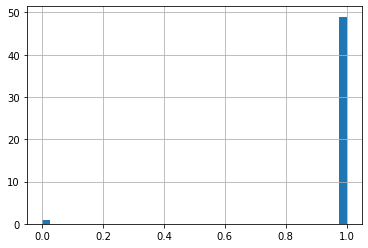

In [30]:
df['energy_scaled'].hist(bins=40)

<AxesSubplot:>

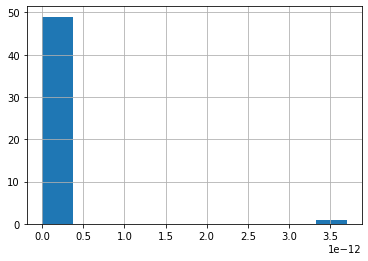

In [31]:
df['calm'].hist()

In [32]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Assuming df is your DataFrame with columns 'happy', 'sad', 'energetic', 'calm'
# You may need to adjust the column names or use the actual DataFrame structure

# Select the columns for clustering
columns_for_clustering = ['happy', 'sad', 'energetic', 'calm']

# Extract the feature matrix
X = df[columns_for_clustering]

# Standardize the feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Specify the number of clusters
num_clusters = 5

# Apply K-Means clustering
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Display the resulting DataFrame with cluster assignments
df

/Users/jojorugjosie/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/validation.py:571: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  array.dtypes.apply(is_sparse).any()):
/Users/jojorugjosie/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/validation.py:571: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  array.dtypes.apply(is_sparse).any()):


,spotify id,artist ids,track name,album name,artist name(s),release date,duration (ms),popularity,added by,added at,...,valence,tempo,time signature,sad,happy,energetic,calm,energy_scaled,calm_scaled,cluster
0,4sigEqg7SMeZsn8haXoloU,6zGCrS2y63IEUJfyn9Bpuc,Wonderwall,Wonderwall,TEEMID,2020-05-27,246169,65,spotify:user:,1970-01-01T00:00:00Z,...,0.5210,99.970,4,0.24,0.660,1.0,1.783299e-19,1.000000,0.00000,2
1,6eOc4UyJok1C0t3mur8GYD,4NTnwCK3RqTBH7TFIQrkfL,I See You,I See You,PLÜM,2020-11-13,165161,55,spotify:user:,1970-01-01T00:00:00Z,...,0.2870,93.041,4,0.48,0.440,1.0,7.448980e-16,0.999695,0.00018,0
2,36Qq8d5qOwIwI8MSj3CXQ0,7C3Cbtr2PkH2l4tOGhtCsk,Make Believe,Magical Thinking,Shallou,2020-03-27,174013,61,spotify:user:,1970-01-01T00:00:00Z,...,0.2870,120.005,4,0.55,0.370,1.0,1.847519e-20,1.000000,0.00000,4
3,6PsPrBPvWqyhRCFVIxfCkg,"1SKIyebAAhyPaaFp4x1Vp0,0oeUdHJ3cy1oveb8WguJJt",Dinosaur - OTR Remix,Dinosaur (OTR Remix),"More Giraffes,OTR",2018-06-21,183797,51,spotify:user:,1970-01-01T00:00:00Z,...,0.2090,78.901,4,0.49,0.370,1.0,3.617458e-14,0.990173,0.00978,4
4,7J9SWm2yp6mDmbM4ESRCAQ,"4H6XYH7PhoJXhD45W93wkh,7sosL0rffvNlG2SE0fyZJX",Take Me Dancing,Take Me Dancing,"Mauve,Anica Russo",2021-03-12,140526,65,spotify:user:,1970-01-01T00:00:00Z,...,0.1070,114.010,4,0.84,0.090,1.0,5.870416e-15,0.998352,0.00156,3
5,6kckNpuM5oXZrObLExRg6d,"27gtK7m9vYwCyJ04zz0kIb,0IEPb9ily3E5IAYMSkwtQ6",Road,Brightest Lights,"Lane 8,Arctic Lake",2020-01-10,238032,61,spotify:user:,1970-01-01T00:00:00Z,...,0.0963,121.985,4,0.66,0.160,1.0,1.498606e-18,1.000000,0.00000,3
6,1w9xdgK0XAkAdn31cHPsCL,73L4PEW4FAJ7bsHZHqq4hP,Airplane Mode,Airplane Mode,GEPPS,2020-12-04,115500,58,spotify:user:,1970-01-01T00:00:00Z,...,0.8170,109.962,4,0.35,0.630,1.0,2.967495e-20,1.000000,0.00000,0
7,4PdLup4OaCGktZG8cvbkBz,28yVvEvA2lT3K5RNIhV1Dj,go with u,Someone's EP II,BAYNK,2019-05-22,231192,60,spotify:user:,1970-01-01T00:00:00Z,...,0.3460,108.994,4,0.24,0.700,1.0,2.666870e-20,1.000000,0.00000,2
8,6sgqf4wXFWSAmjL1TEXNvZ,"2vf4pRsEY6LpL5tKmqWb64,4WN5naL3ofxrVBgFpguzKo",Something About You (with Rudimental) - Chill Mix,Something About You (with Rudimental) [Alterna...,"Elderbrook,Rudimental",2019-10-04,166533,64,spotify:user:,1970-01-01T00:00:00Z,...,0.4430,106.122,4,0.42,0.530,1.0,5.036522e-19,1.000000,0.00000,0
9,78vBw8siHaT9TcI5cls1iM,2rdSCmWgrIWA8pmwhS1T2k,Motion,When The Light Breaks,Vandelux,2023-09-15,187990,57,spotify:user:,1970-01-01T00:00:00Z,...,0.2000,120.012,4,0.08,0.650,1.0,1.929137e-24,1.000000,0.00000,2


## Average the outputted happy/sad/energetic/calm vectors

In [33]:
# # Get data for one user
# df_one_user = df[df['Response_Id']==0]
# df_one_user

In [34]:
# user_mood_vector = df_one_user[['happy', 'sad', 'energetic', 'calm']].mean()
user_mood_vector = df[['happy', 'sad', 'energetic', 'calm']].mean()
user_mood_vector

happy        4.033000e-01
sad          4.422000e-01
energetic    1.000000e+00
calm         7.533368e-14
dtype: float64

In [35]:
# Reshape mood vector for cosine similarity 
user_mood_reshaped = user_mood_vector.values.reshape(1, -1)

## Load movie data and perform cosine similarity to get top 5 movie recommendations

#### NOTE: Make sure you unzip file below before reading

In [36]:
import zipfile
import os

# Specify the path to the zip file
zip_file_path = '../data/raw/wiki_movies_mood_label_by_gpt-3.5-turbo_final.csv.zip'

# Specify the directory where you want to extract the contents
extracted_dir = '../data/raw/'

# Create the extraction directory if it doesn't exist
os.makedirs(extracted_dir, exist_ok=True)

# Open the zip file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    # Extract all the contents into the specified directory
    zip_ref.extractall(extracted_dir)

print(f"Successfully extracted contents to {extracted_dir}")

Successfully extracted contents to ../data/raw/


In [37]:
movie_df = pd.read_csv('../data/raw/wiki_movies_mood_label_by_gpt-3.5-turbo_final.csv').loc[:,'year':]
movie_df

,year,href,title,plot,premise,synopsis,directed_by,screenplay_by,based_on,starring,...,roi,roi_binary,roi_multi,rt_binary,rt_multi,happy,sad,energetic,calm,error_labeling
0,1973,40_Carats_(film),40 Carats (film),"Ann Stanley, who sells real estate in New York...",NaN,NaN,Directed byMilton Katselas,Screenplay byLeonard Gershe,Based on\nQuarante caratsby Pierre BarilletJea...,Starring\nLiv Ullmann\nEdward Albert\nGene Kel...,...,NaN,0,0,0,0,0.8,0.3,0.6,0.7,NaN
1,1973,Ace_Eli_and_Rodger_of_the_Skies,Ace Eli and Rodger of the Skies,"In the early 1920s, Eli (Cliff Robertson) is a...",NaN,NaN,Directed byJohn Erman,Screenplay byClaudia Salter,NaN,Starring\nCliff Robertson\nEric Shea\nPamela F...,...,NaN,0,0,0,0,0.7,0.6,0.8,0.5,NaN
2,1973,The_Affair_(1973_film),The Affair (1973 film),Courtney Patterson is a beautiful 32 year old ...,NaN,NaN,Directed byGilbert Cates,NaN,NaN,StarringNatalie WoodRobert WagnerBruce Davison...,...,NaN,0,0,0,0,0.5,0.8,0.4,0.7,NaN
3,1973,The_All-American_Boy_(film),The All-American Boy (film),"Vic Bealer, a young boxer from a small town in...",NaN,NaN,Directed byCharles Eastman,NaN,NaN,StarringJon VoightE. J. Peaker,...,NaN,0,0,0,0,0.2,0.6,0.8,0.4,NaN
4,1973,American_Graffiti,American Graffiti,On their last evening of summer vacation in 19...,NaN,NaN,Directed byGeorge Lucas,NaN,NaN,Starring\nRichard Dreyfuss\nRon Howard\nPaul L...,...,180.18018,1,2,1,2,0.5,0.7,0.7,0.5,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11933,2023,Rebel_Moon,Rebel Moon,NaN,In a universe controlled by the corrupt govern...,NaN,Directed byZack Snyder,Screenplay by\nZack Snyder\nKurt Johnstad\nSha...,NaN,Starring\nSofia Boutella\nCharlie Hunnam\nMich...,...,NaN,0,0,0,0,0.3,0.4,0.8,0.5,NaN
11934,2023,The_Iron_Claw_(film),The Iron Claw (film),NaN,NaN,The film is centered around the Von Erich fami...,Directed bySean Durkin,NaN,NaN,Starring\nZac Efron\nJeremy Allen White\nHarri...,...,NaN,0,0,0,0,0.3,0.7,0.8,0.2,NaN
11935,2023,The_Color_Purple_(2023_film),The Color Purple (2023 film),NaN,A story of the life-long struggles of an Afric...,NaN,Directed byBlitz Bazawule,Screenplay byMarcus Gardley,Based on\nThe Color Purpleby Alice Walker\nThe...,Starring\nTaraji P. Henson\nDanielle Brooks\nC...,...,NaN,0,0,0,0,0.1,0.9,0.2,0.8,NaN
11936,2023,The_Boys_in_the_Boat_(film),The Boys in the Boat (film),The non-fiction novel describes the University...,NaN,NaN,Directed byGeorge Clooney,Screenplay byMark L. Smith,Based onThe Boys in the Boatby Daniel James Brown,Starring\nCallum Turner\nJoel Edgerton\n,...,NaN,0,0,0,0,0.2,0.7,0.8,0.4,NaN


In [38]:
movie_df.columns

Index(['year', 'href', 'title', 'plot', 'premise', 'synopsis', 'directed_by',
       'screenplay_by', 'based_on', 'starring', 'box_office', 'written_by',
       'budget', 'omdb_response', 'omdb_title', 'genres', 'omdb_plot',
       'release_date', 'omdb_director', 'omdb_writer', 'omdb_actors',
       'imdb_score', 'imdb_votes', 'rotten_tomatoes_score', 'metacritic_score',
       'directed_by_clean', 'screenplay_by_clean', 'written_by_clean',
       'starring_clean', 'based_on_binary', 'based_on_binary_characters',
       'based_on_binary_comic_books', 'box_office_clean', 'budget_clean',
       'chosen_plot_feature', 'writers_to_use', 'actors_to_use',
       'plot_parenthetical', 'num_parentheticals',
       'plot_parenthetical_fuzzy_scores', 'new_plot',
       'all_writers_first_movie', 'any_writers_first_movie', 'roi',
       'roi_binary', 'roi_multi', 'rt_binary', 'rt_multi', 'happy', 'sad',
       'energetic', 'calm', 'error_labeling'],
      dtype='object')

In [39]:
#movie_df = movie_df[movie_df['year'] >= 1995]

In [40]:
# Load mood vectors for movies
movie_mood_vectors = movie_df[['happy','sad','energetic','calm']].values
movie_mood_vectors

array([[0.8, 0.3, 0.6, 0.7],
       [0.7, 0.6, 0.8, 0.5],
       [0.5, 0.8, 0.4, 0.7],
       ...,
       [0.1, 0.9, 0.2, 0.8],
       [0.2, 0.7, 0.8, 0.4],
       [0.7, 0.3, 0.9, 0.4]])

### Simple cosine similarity

In [41]:

# Iterate over each cluster
for user_cluster in range(5):
    # Step 2: Calculate the average mood vector for each cluster
    cluster_avg_mood = df.groupby('cluster')[['sad', 'happy', 'energetic', 'calm']].mean()

    # Reshape the user's cluster average mood vector
    user_mood_reshaped = cluster_avg_mood.loc[user_cluster].values.reshape(1, -1)

    # Step 3: Use cosine similarity to find the top movies similar to the average mood vectors of the clusters
    similarities = cosine_similarity(user_mood_reshaped, movie_mood_vectors)
    sim_scores = list(enumerate(similarities[0]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Get top movie titles based on top similarity scores
    top_movies = sim_scores[1][0]
#     top_movie_indices = [i[0] for i in top_movies]
    recommended_movies = movie_df.iloc[top_movies]
    print(recommended_movies)


year                                                                            1974
href                                                          Sugar_Hill_(1974_film)
title                                                         Sugar Hill (1974 film)
plot                               The story centers on Diana "Sugar" Hill (Bey),...
premise                                                                          NaN
synopsis                                                                         NaN
directed_by                                                Directed byPaul Maslansky
screenplay_by                                                                    NaN
based_on                                                                         NaN
starring                           Starring\nMarki Bey\nRobert Quarry\nDon Pedro ...
box_office                                                                       NaN
written_by                                                       

In [42]:
# Perform cosine similarity to get top 5 similar movies based on mood vector
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(user_mood_reshaped, movie_mood_vectors)
sim_scores = list(enumerate(similarities[0]))
sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

# Get top movie titles based on top similarity scores
top_movies = sim_scores[1:6]
top_movie_indices = [i[0] for i in top_movies]
recommended_movies = movie_df.iloc[top_movie_indices]
recommended_movies

,year,href,title,plot,premise,synopsis,directed_by,screenplay_by,based_on,starring,...,roi,roi_binary,roi_multi,rt_binary,rt_multi,happy,sad,energetic,calm,error_labeling
8462,2010,Videocracy_(film),Videocracy (film),The Italian veline phenomenon is explained. We...,NaN,NaN,Directed byErik Gandini,NaN,NaN,StarringSilvio BerlusconiFlavio BriatoreFabriz...,...,NaN,0,0,0,0,0.4,0.2,0.7,0.1,NaN
11149,2021,America:_The_Motion_Picture,America: The Motion Picture,"In July 1776, just after signing the Declarati...",NaN,NaN,Directed byMatt Thompson,NaN,NaN,Starring\nChanning Tatum\nJason Mantzoukas\nOl...,...,NaN,0,0,0,0,0.5,0.2,0.8,0.1,NaN
493,1976,Bobbie_Jo_and_the_Outlaw,Bobbie Jo and the Outlaw,A young wannabe country singer named Bobbie Jo...,NaN,NaN,Directed byMark L. Lester,NaN,NaN,StarringLynda Carter Marjoe Gortner,...,NaN,0,0,0,0,0.3,0.2,0.7,0.1,NaN
1874,1984,Ninja_III:_The_Domination,Ninja III: The Domination,"Christie Ryder (Dickey), a telephone linewoman...",NaN,NaN,Directed bySam Firstenberg[1],NaN,NaN,Starring\nSho Kosugi\nLucinda Dickey\nJordan B...,...,3.805392,1,2,0,0,0.3,0.2,0.7,0.1,NaN
7878,2008,Zombie_Strippers,Zombie Strippers,The film opens with a news montage showing a d...,NaN,NaN,Directed byJay Lee,NaN,NaN,Starring\nRobert Englund\nJenna Jameson\nPenny...,...,NaN,0,0,0,0,0.3,0.2,0.7,0.1,NaN


### Alternate 2: Cosine similarity + popularity filter + after 1995

In [43]:
for user_cluster in range(5):
    # Step 2: Calculate the average mood vector for each cluster
    cluster_avg_mood = df.groupby('cluster')[['sad', 'happy', 'energetic', 'calm']].mean()

    # Reshape the user's cluster average mood vector
    user_mood_reshaped = cluster_avg_mood.loc[user_cluster].values.reshape(1, -1)
    similarities = cosine_similarity(user_mood_reshaped, movie_mood_vectors)
    sim_scores = list(enumerate(similarities[0]))

    # Filter movies released in 1995 or after
    eligible_movies = [i for i in sim_scores if movie_df.loc[i[0], 'year'] >= 1995]

    # Sort by cosine similarity and popularity score
    eligible_movies = sorted(eligible_movies, key=lambda x: (x[1], movie_df.loc[x[0], 'rotten_tomatoes_score']), reverse=True)

    # Filter out NaN values and select top movies
    top_movies = [i for i in eligible_movies if not pd.isna(movie_df.loc[i[0], 'rotten_tomatoes_score']) or not pd.isna(movie_df.loc[i[0], 'metacritic_score'])][:5]
    top_movie_indices = [i[0] for i in top_movies]
    recommended_movies = movie_df.iloc[top_movie_indices]
    print(recommended_movies)

       year              href             title  \
10036  2017         XX_(film)         XX (film)   
7448   2006      Crank_(film)      Crank (film)   
7897   2008         War,_Inc.         War, Inc.   
7878   2008  Zombie_Strippers  Zombie Strippers   
10667  2019          Low_Tide          Low Tide   

                                                    plot premise synopsis  \
10036                                                NaN     NaN      NaN   
7448   Chev Chelios is a Los Angeles-based British hi...     NaN      NaN   
7897   The film opens in a bar in Nunavut when hitman...     NaN      NaN   
7878   The film opens with a news montage showing a d...     NaN      NaN   
10667                                                NaN     NaN      NaN   

                                             directed_by screenplay_by  \
10036  Directed by\nJovanka Vuckovic\nAnnie Clark\nRo...           NaN   
7448                         Directed byNeveldine/Taylor           NaN   
7897    

       year                         href                        title  \
11149  2021  America:_The_Motion_Picture  America: The Motion Picture   
7878   2008             Zombie_Strippers             Zombie Strippers   
10667  2019                     Low_Tide                     Low Tide   
5593   1998             Knock_Off_(film)             Knock Off (film)   
9543   2014             Lucy_(2014_film)             Lucy (2014 film)   

                                                    plot premise synopsis  \
11149  In July 1776, just after signing the Declarati...     NaN      NaN   
7878   The film opens with a news montage showing a d...     NaN      NaN   
10667                                                NaN     NaN      NaN   
5593   Russian agents searching for something underwa...     NaN      NaN   
9543   Lucy is an American studying in Taipei, Taiwan...     NaN      NaN   

                     directed_by screenplay_by based_on  \
11149   Directed byMatt Thompson       

In [44]:
similarities = cosine_similarity(user_mood_reshaped, movie_mood_vectors)
sim_scores = list(enumerate(similarities[0]))

# Filter movies released in 1995 or after
eligible_movies = [i for i in sim_scores if movie_df.loc[i[0], 'year'] >= 1995]

# Sort by cosine similarity and popularity score
eligible_movies = sorted(eligible_movies, key=lambda x: (x[1], movie_df.loc[x[0], 'rotten_tomatoes_score']), reverse=True)

# Filter out NaN values and select top movies
top_movies = [i for i in eligible_movies if not pd.isna(movie_df.loc[i[0], 'rotten_tomatoes_score']) or not pd.isna(movie_df.loc[i[0], 'metacritic_score'])][:5]
top_movie_indices = [i[0] for i in top_movies]
recommended_movies = movie_df.iloc[top_movie_indices]
recommended_movies

,year,href,title,plot,premise,synopsis,directed_by,screenplay_by,based_on,starring,...,roi,roi_binary,roi_multi,rt_binary,rt_multi,happy,sad,energetic,calm,error_labeling
11149,2021,America:_The_Motion_Picture,America: The Motion Picture,"In July 1776, just after signing the Declarati...",NaN,NaN,Directed byMatt Thompson,NaN,NaN,Starring\nChanning Tatum\nJason Mantzoukas\nOl...,...,NaN,0,0,0,0,0.5,0.2,0.8,0.1,NaN
7878,2008,Zombie_Strippers,Zombie Strippers,The film opens with a news montage showing a d...,NaN,NaN,Directed byJay Lee,NaN,NaN,Starring\nRobert Englund\nJenna Jameson\nPenny...,...,NaN,0,0,0,0,0.3,0.2,0.7,0.1,NaN
10667,2019,Low_Tide,Low Tide,NaN,NaN,NaN,Directed byKevin McMullin,NaN,NaN,Starring\nKeean Johnson\nAlex Neustaedter\nDan...,...,NaN,0,0,1,0,0.3,0.2,0.6,0.1,NaN
5593,1998,Knock_Off_(film),Knock Off (film),Russian agents searching for something underwa...,NaN,NaN,Directed byTsui Hark,NaN,NaN,Starring\nJean-Claude Van Damme\nRob Schneider...,...,1.257143,1,1,0,0,0.3,0.2,0.8,0.1,NaN
9543,2014,Lucy_(2014_film),Lucy (2014 film),"Lucy is an American studying in Taipei, Taiwan...",NaN,NaN,Directed byLuc Besson,NaN,NaN,Starring\nScarlett Johansson\nMorgan Freeman\n...,...,11.725000,1,2,1,0,0.6,0.3,0.8,0.1,NaN


### Alternate 3: Cosine similarity + popularity filter

In [45]:
for user_cluster in range(5):
    # Step 2: Calculate the average mood vector for each cluster
    cluster_avg_mood = df.groupby('cluster')[['sad', 'happy', 'energetic', 'calm']].mean()

    # Reshape the user's cluster average mood vector
    user_mood_reshaped = cluster_avg_mood.loc[user_cluster].values.reshape(1, -1)
    similarities = cosine_similarity(user_mood_reshaped, movie_mood_vectors)
    sim_scores = list(enumerate(similarities[0]))


    # Sort by cosine similarity and popularity score
    eligible_movies = sorted(sim_scores, key=lambda x: (x[1], movie_df.loc[x[0], 'rotten_tomatoes_score']), reverse=True)

    # Filter out NaN values and select top movies
    top_movies = [i for i in eligible_movies if not pd.isna(movie_df.loc[i[0], 'rotten_tomatoes_score']) or not pd.isna(movie_df.loc[i[0], 'metacritic_score'])][:5]
    top_movie_indices = [i[0] for i in top_movies]
    recommended_movies = movie_df.iloc[top_movie_indices]
    print(recommended_movies)

       year                    href                   title  \
3464   1990  The_Rookie_(1990_film)  The Rookie (1990 film)   
304    1974  Sugar_Hill_(1974_film)  Sugar Hill (1974 film)   
10036  2017               XX_(film)               XX (film)   
7448   2006            Crank_(film)            Crank (film)   
7897   2008               War,_Inc.               War, Inc.   

                                                    plot premise synopsis  \
3464   Nick Pulovski (Clint Eastwood) and his partner...     NaN      NaN   
304    The story centers on Diana "Sugar" Hill (Bey),...     NaN      NaN   
10036                                                NaN     NaN      NaN   
7448   Chev Chelios is a Los Angeles-based British hi...     NaN      NaN   
7897   The film opens in a bar in Nunavut when hitman...     NaN      NaN   

                                             directed_by screenplay_by  \
3464                           Directed byClint Eastwood           NaN   
304       

       year                         href                        title  \
11149  2021  America:_The_Motion_Picture  America: The Motion Picture   
1874   1984    Ninja_III:_The_Domination    Ninja III: The Domination   
7878   2008             Zombie_Strippers             Zombie Strippers   
10667  2019                     Low_Tide                     Low Tide   
5593   1998             Knock_Off_(film)             Knock Off (film)   

                                                    plot premise synopsis  \
11149  In July 1776, just after signing the Declarati...     NaN      NaN   
1874   Christie Ryder (Dickey), a telephone linewoman...     NaN      NaN   
7878   The film opens with a news montage showing a d...     NaN      NaN   
10667                                                NaN     NaN      NaN   
5593   Russian agents searching for something underwa...     NaN      NaN   

                         directed_by screenplay_by based_on  \
11149       Directed byMatt Thompso

In [46]:
similarities = cosine_similarity(user_mood_reshaped, movie_mood_vectors)
sim_scores = list(enumerate(similarities[0]))


# Sort by cosine similarity and popularity score
eligible_movies = sorted(sim_scores, key=lambda x: (x[1], movie_df.loc[x[0], 'rotten_tomatoes_score']), reverse=True)

# Filter out NaN values and select top movies
top_movies = [i for i in eligible_movies if not pd.isna(movie_df.loc[i[0], 'rotten_tomatoes_score']) or not pd.isna(movie_df.loc[i[0], 'metacritic_score'])][:5]
top_movie_indices = [i[0] for i in top_movies]
recommended_movies = movie_df.iloc[top_movie_indices]
recommended_movies

,year,href,title,plot,premise,synopsis,directed_by,screenplay_by,based_on,starring,...,roi,roi_binary,roi_multi,rt_binary,rt_multi,happy,sad,energetic,calm,error_labeling
11149,2021,America:_The_Motion_Picture,America: The Motion Picture,"In July 1776, just after signing the Declarati...",NaN,NaN,Directed byMatt Thompson,NaN,NaN,Starring\nChanning Tatum\nJason Mantzoukas\nOl...,...,NaN,0,0,0,0,0.5,0.2,0.8,0.1,NaN
1874,1984,Ninja_III:_The_Domination,Ninja III: The Domination,"Christie Ryder (Dickey), a telephone linewoman...",NaN,NaN,Directed bySam Firstenberg[1],NaN,NaN,Starring\nSho Kosugi\nLucinda Dickey\nJordan B...,...,3.805392,1,2,0,0,0.3,0.2,0.7,0.1,NaN
7878,2008,Zombie_Strippers,Zombie Strippers,The film opens with a news montage showing a d...,NaN,NaN,Directed byJay Lee,NaN,NaN,Starring\nRobert Englund\nJenna Jameson\nPenny...,...,NaN,0,0,0,0,0.3,0.2,0.7,0.1,NaN
10667,2019,Low_Tide,Low Tide,NaN,NaN,NaN,Directed byKevin McMullin,NaN,NaN,Starring\nKeean Johnson\nAlex Neustaedter\nDan...,...,NaN,0,0,1,0,0.3,0.2,0.6,0.1,NaN
5593,1998,Knock_Off_(film),Knock Off (film),Russian agents searching for something underwa...,NaN,NaN,Directed byTsui Hark,NaN,NaN,Starring\nJean-Claude Van Damme\nRob Schneider...,...,1.257143,1,1,0,0,0.3,0.2,0.8,0.1,NaN


Create 3 columns for movie1, movie2, movie3

In [ ]:
df

Loop through all tracks, transform track mood vector, predict movies, append top 3 movies to dataframe

In [ ]:
mv = df.loc[0, ['happy','sad','energetic','calm']]

In [ ]:
mv

In [ ]:
umr = mv.values.reshape(1, -1)

In [ ]:
similarities = cosine_similarity(umr, movie_mood_vectors)
sim_scores = list(enumerate(similarities[0]))
eligible_movies = sorted(sim_scores, key=lambda x: (x[1], movie_df.loc[x[0], 'rotten_tomatoes_score']), reverse=True)
# Filter out NaN values and select top movies
top_movies = [i for i in eligible_movies if not pd.isna(movie_df.loc[i[0], 'rotten_tomatoes_score']) or not pd.isna(movie_df.loc[i[0], 'metacritic_score'])][:5]
top_movie_indices = [i[0] for i in top_movies]
recommended_movies = movie_df.iloc[top_movie_indices]


In [ ]:
movie_df.loc[top_movie_indices[0]]['title']

In [ ]:
df['movie1'] = ''

In [ ]:
df['movie2'] = ''
df['movie3']= ''

In [ ]:
df.loc[0,'movie1'] = movie_df.loc[top_movie_indices[0],'title']

In [ ]:
df

In [ ]:
for i in range(len(df)):
    mv = df.loc[i, ['happy','sad','energetic','calm']]
    umr = mv.values.reshape(1, -1)
    similarities = cosine_similarity(umr, movie_mood_vectors)
    sim_scores = list(enumerate(similarities[0]))
    eligible_movies = sorted(sim_scores, key=lambda x: (x[1], movie_df.loc[x[0], 'rotten_tomatoes_score']), reverse=True)
    # Filter out NaN values and select top movies
    top_movies = [i for i in eligible_movies if not pd.isna(movie_df.loc[i[0], 'rotten_tomatoes_score']) or not pd.isna(movie_df.loc[i[0], 'metacritic_score'])][:5]
    top_movie_indices = [i[0] for i in top_movies]
    # append top 3 movies to df
    df.loc[i,'movie1'] = movie_df.loc[top_movie_indices[0],'title']
    df.loc[i,'movie2'] = movie_df.loc[top_movie_indices[1],'title']
    df.loc[i,'movie3'] = movie_df.loc[top_movie_indices[2],'title']
    

In [ ]:
df

In [ ]:
# df.to_csv('will2019_labeled_v3.csv', index=False)